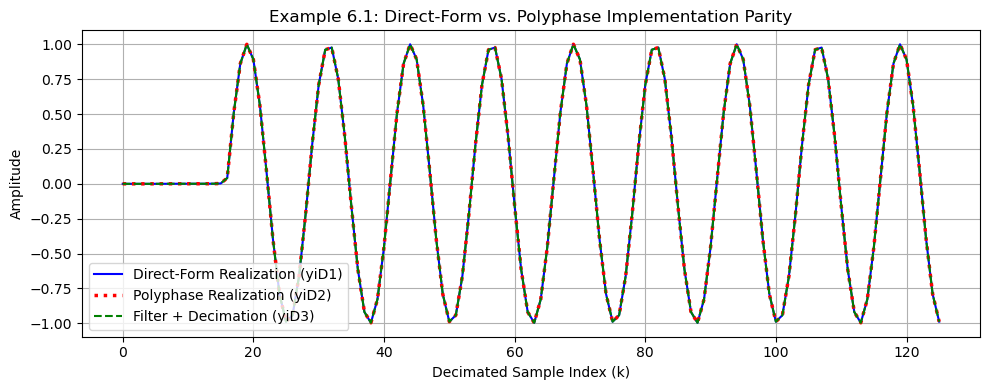

Max difference (Direct vs Polyphase)           : 3.33e-16
Max difference (Direct vs Filter+Decimation)   : 2.22e-16


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, lfilter

# ==========================================
# 1. Setup Parameters & Input Signal
# ==========================================
n_samples = 1001
ui = np.sin(2 * np.pi * 0.01 * np.arange(n_samples)) # Sine wave input signal
N = 8                                                # Number of subbands
M = 256                                              # Length of filter
w = firwin(M, cutoff=1.0 / 4.0, fs=2.0)              # Target weight vector

# ==========================================
# 2. Direct-Form Realization
# ==========================================
x_direct = np.zeros(M)
yiD1 = []
for n in range(n_samples):
    x_direct = np.concatenate(([ui[n]], x_direct[:-1])) # Update tapped-delay line
    if n % N == 0:
        yiD1.append(np.dot(w, x_direct))               # Direct-form output at decimation rate
yiD1 = np.array(yiD1)

# ==========================================
# 3. Polyphase Realization
# ==========================================
# Polyphase decomposition (reshaping into N rows x (M/N) columns using Fortran order)
W_poly = w.reshape(N, M // N, order='F')
X_poly = np.zeros((N, M // N))
xN_buf = np.zeros(N)

yiD2 = []
for n in range(n_samples):
    xN_buf = np.concatenate(([ui[n]], xN_buf[:-1]))
    if n % N == 0:
        X_poly = np.hstack((xN_buf.reshape(-1, 1), X_poly[:, :-1])) # Update polyphase buffer
        yiD2.append(np.sum(W_poly * X_poly))                         # Polyphase sum output
yiD2 = np.array(yiD2)

# ==========================================
# 4. Standard Filtering followed by Decimation
# ==========================================
yi3 = lfilter(w, [1.0], ui)
yiD3 = yi3[::N]

# ==========================================
# 5. Parity Verification & Plotting
# ==========================================
plt.figure(figsize=(10, 4))
plt.plot(yiD1, 'b', label='Direct-Form Realization (yiD1)')
plt.plot(yiD2, 'r:', label='Polyphase Realization (yiD2)', linewidth=2.5)
plt.plot(yiD3, 'g--', label='Filter + Decimation (yiD3)', linewidth=1.5)
plt.title('Example 6.1: Direct-Form vs. Polyphase Implementation Parity')
plt.xlabel('Decimated Sample Index (k)'); plt.ylabel('Amplitude')
plt.grid(True); plt.legend(); plt.tight_layout()
plt.show()

# Verification check
max_diff_12 = np.max(np.abs(yiD1 - yiD2))
max_diff_13 = np.max(np.abs(yiD1 - yiD3))
print(f"Max difference (Direct vs Polyphase)           : {max_diff_12:.2e}")
print(f"Max difference (Direct vs Filter+Decimation)   : {max_diff_13:.2e}")

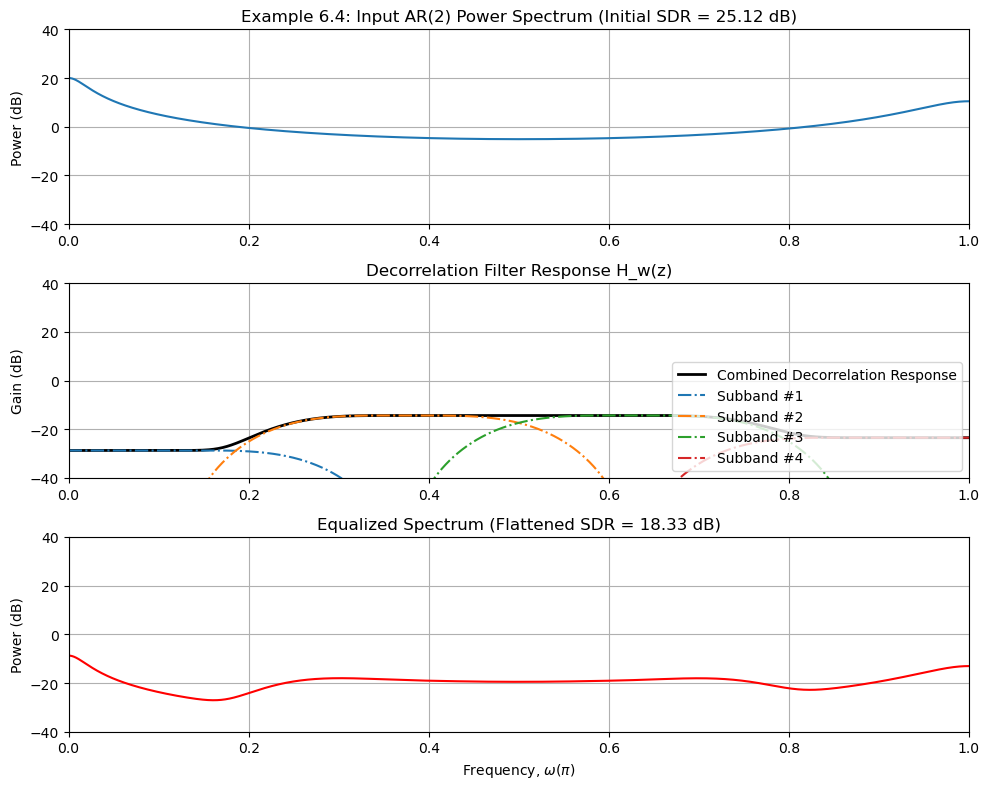

--- Example 6.4 Results ---
Input Spectral Dynamic Range (SDR)     : 25.1190 dB
Equalized Spectral Dynamic Range (SDR) : 18.3280 dB


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import remez, lfilter

# ==========================================
# 1. Helper Functions
# ==========================================
def opt_filter(filtorder: int, N: int):
    """Optimal prototype lowpass FIR filter design."""
    stopedge = 1.0 / N
    passedge = 1.0 / (4 * N)
    tol = 1e-6
    step = 0.1 * passedge
    way = -1
    pcost = 10.0
    flag = False

    while not flag:
        p = remez(filtorder + 1, [0, passedge, stopedge, 1.0], [1, 0], weight=[5, 1], fs=2.0)
        P = np.fft.fft(p, 4096)
        OptRange = int(np.floor(2048 / N))
        phi = np.zeros(OptRange)
        for k in range(1, OptRange + 1):
            phi[k - 1] = np.abs(P[OptRange - k + 1])**2 + np.abs(P[k - 1])**2
        tcost = np.max(np.abs(phi - 1.0))
        if tcost > pcost:
            step /= 2.0
            way = -way
        if np.abs(pcost - tcost) < tol:
            flag = True
        pcost = tcost
        passedge += way * step
    return p, passedge

def make_bank(p: np.ndarray, N: int):
    """Cosine-modulated analysis filter bank."""
    L = len(p)
    H = np.zeros((N, L))
    n = np.arange(L)
    for i in range(N):
        H[i, :] = 2 * p * np.cos((np.pi / N) * (i + 0.5) * (n - (L - 1) / 2.0) + ((-1)**i) * (np.pi / 4.0))
    return H

# ==========================================
# 2. Parameters & Signal Generation (6P4)
# ==========================================
M_taps = 1024                         # Adaptive filter length
N_sub = 4                             # Number of subbands (N = 4)
L_sub = 8 * N_sub                     # Filter bank length (L = 32)

# Generate AR(2) colored process excitation
np.random.seed(42)
wn = np.random.randn(80000)
a = np.array([1.0, -0.1, -0.8])
un = lfilter([1.0], a, wn)
un /= np.std(un)                      # Normalize to unit variance

# ==========================================
# 3. Filter Bank & Frequency Response Computation
# ==========================================
hopt, _ = opt_filter(L_sub - 1, N_sub)
H_bank = np.sqrt(N_sub) * make_bank(hopt, N_sub)

DFTpoint = 4096
w_freq = np.linspace(0, np.pi, DFTpoint // 2 + 1)

# Input signal power spectrum S_uu(e^{j\omega})
A_resp = np.fft.fft(a, DFTpoint)[:DFTpoint // 2 + 1]
HzSig = 1.0 / (np.abs(A_resp)**2)
HzSig /= np.var(un)

# Subband filter magnitude responses |H_i(e^{j\omega})|^2
Hz_mag = np.zeros((N_sub, DFTpoint // 2 + 1))
for i in range(N_sub):
    H_fft = np.fft.fft(H_bank[i, :], DFTpoint)[:DFTpoint // 2 + 1]
    Hz_mag[i, :] = np.abs(H_fft)**2

# Compute equivalent decorrelation filter responses
weight = np.zeros(N_sub)
Hw = np.zeros((N_sub, DFTpoint // 2 + 1))

for i in range(N_sub):
    un_i = lfilter(H_bank[i, :], [1.0], un)
    weight[i] = np.var(un_i) * M_taps
    Hw[i, :] = Hz_mag[i, :] / weight[i]

HwSum = np.sum(Hw, axis=0)
HzSigNor = HzSig * HwSum

# Compute Spectral Dynamic Range (SDR)
SDR_in = 10 * np.log10(np.max(HzSig)) - 10 * np.log10(np.min(HzSig))
SDR_out = 10 * np.log10(np.max(HzSigNor)) - 10 * np.log10(np.min(HzSigNor))

# ==========================================
# 4. Plotting Results
# ==========================================
plt.figure(figsize=(10, 8))

# Subplot 1: Input AR(2) Spectrum
plt.subplot(3, 1, 1)
plt.plot(w_freq / np.pi, 10 * np.log10(HzSig + 1e-12))
plt.title(f'Example 6.4: Input AR(2) Power Spectrum (Initial SDR = {SDR_in:.2f} dB)')
plt.ylabel('Power (dB)'); plt.xlim([0, 1]); plt.ylim([-40, 40]); plt.grid(True)

# Subplot 2: Decorrelation Filter Responses
plt.subplot(3, 1, 2)
plt.plot(w_freq / np.pi, 10 * np.log10(HwSum + 1e-12), 'k', linewidth=2.0, label='Combined Decorrelation Response')
for i in range(N_sub):
    plt.plot(w_freq / np.pi, 10 * np.log10(Hw[i, :] + 1e-12), '-.', label=f'Subband #{i+1}')
plt.title('Decorrelation Filter Response H_w(z)')
plt.ylabel('Gain (dB)'); plt.xlim([0, 1]); plt.ylim([-40, 40]); plt.grid(True); plt.legend(loc='lower right')

# Subplot 3: Equalized / Flattened Spectrum
plt.subplot(3, 1, 3)
plt.plot(w_freq / np.pi, 10 * np.log10(HzSigNor + 1e-12), 'r')
plt.title(f'Equalized Spectrum (Flattened SDR = {SDR_out:.2f} dB)')
plt.xlabel(r'Frequency, $\omega (\pi)$'); plt.ylabel('Power (dB)'); plt.xlim([0, 1]); plt.ylim([-40, 40]); plt.grid(True)

plt.tight_layout()
plt.show()

print(f"--- Example 6.4 Results ---")
print(f"Input Spectral Dynamic Range (SDR)     : {SDR_in:.4f} dB")
print(f"Equalized Spectral Dynamic Range (SDR) : {SDR_out:.4f} dB")

In [9]:
import numpy as np

# ==========================================
# Cell 3: MSAF Core Engine (Fixed Buffer Reshaping)
# ==========================================
class MSAF:
    def __init__(self, w0: np.ndarray, mu: float, N: int, L: int, H: np.ndarray = None, F: np.ndarray = None):
        self.w0 = w0.flatten()
        self.M = len(self.w0)
        self.mu = mu
        self.N = N
        self.L = L
        
        if H is None or F is None:
            p0, _ = opt_filter(L - 1, N)
            H_bank = make_bank(p0, N)
            F_bank = np.fliplr(H_bank)
            self.H = np.sqrt(N) * H_bank.T       # (L, N) matrix
            self.F = np.sqrt(N) * F_bank.T       # (L, N) matrix
        else:
            self.H = H
            self.F = F
            
        self.coeffs = self.w0.copy()
        self.alpha = np.ones(N) * 1e-4
        self.AdaptStart = L + self.M
        self.iter = 0

    def adapt(self, un: np.ndarray, dn: np.ndarray, unknownsys: np.ndarray = None):
        ITER = len(un)
        en = np.zeros(ITER)
        w = self.coeffs.copy()
        
        U = np.zeros((self.M, self.N))
        a_buf = np.zeros(self.L)
        d_buf = np.zeros(self.L)
        A_buf = np.zeros((self.L, self.N))
        z_buf = np.zeros(self.L)
        
        compute_eml = unknownsys is not None
        eml = np.zeros(ITER) if compute_eml else None
        if compute_eml:
            norm_b = np.linalg.norm(unknownsys)
            
        for n in range(ITER):
            d_buf = np.concatenate(([dn[n]], d_buf[:-1]))
            a_buf = np.concatenate(([un[n]], a_buf[:-1]))
            A_buf = np.hstack((a_buf.reshape(-1, 1), A_buf[:, :-1]))
            
            if compute_eml:
                eml[n] = np.linalg.norm(unknownsys - w) / norm_b
                
            if (n + 1) % self.N == 0:
                U1 = (self.H.T @ A_buf).T               # (N, L) -> (N, N) block
                U2 = U[:-self.N, :] if self.M > self.N else np.zeros((0, self.N))
                U = np.vstack((U1, U2))                # Stack along row axis to form (M, N) matrix
                
                dD = self.H.T @ d_buf                  # Partitioned desired vector (N,)
                eD = dD - U.T @ w                      # Error estimation vector (N,)
                
                if (n + 1) >= self.AdaptStart:
                    denom = np.sum(U * U, axis=0) + self.alpha
                    w += U @ (eD / denom) * self.mu
                    self.iter += 1
                    
                z_buf = self.F @ eD + z_buf
                en[n - self.N + 1 : n + 1] = z_buf[:self.N]
                z_buf = np.concatenate((z_buf[self.N:], np.zeros(self.N)))
                
        self.coeffs = w
        return en, eml

In [7]:
from scipy.signal import lfilter

# ==========================================
# Cell 4: Signal Generator
# ==========================================
def generate_responses(iter_samples: int, b: np.ndarray, seed: int = 42, ARtype: int = 1, SNR: float = 40.0):
    np.random.seed(seed)
    un_raw = np.random.randn(iter_samples)
    
    AR_dict = {
        1: [1.0],
        2: [1.0, -0.1, -0.8],
        3: [1.0, -1.6, 0.81],
        4: [5.3217, -9.2948, 7.0933, -2.8152, 2.5805, -2.4230, 0.3747, 2.2628, -0.3028, -1.7444, 1.1053]
    }
    a_coeff = AR_dict.get(ARtype, [1.0])
    
    un = lfilter([1.0], a_coeff, un_raw)
    dn = lfilter(b, [1.0], un)
    
    dn = dn[len(b):]
    un = un[len(b):]
    
    std_d = np.std(dn)
    un /= std_d
    dn /= std_d
    
    if SNR < 100:
        noise_var = 10.0 ** (-SNR / 10.0)
        vn = (np.random.rand(len(dn)) - 0.5) * np.sqrt(12.0 * noise_var)
        dn += vn
    else:
        vn = np.zeros(len(dn))
        
    return un, dn, vn

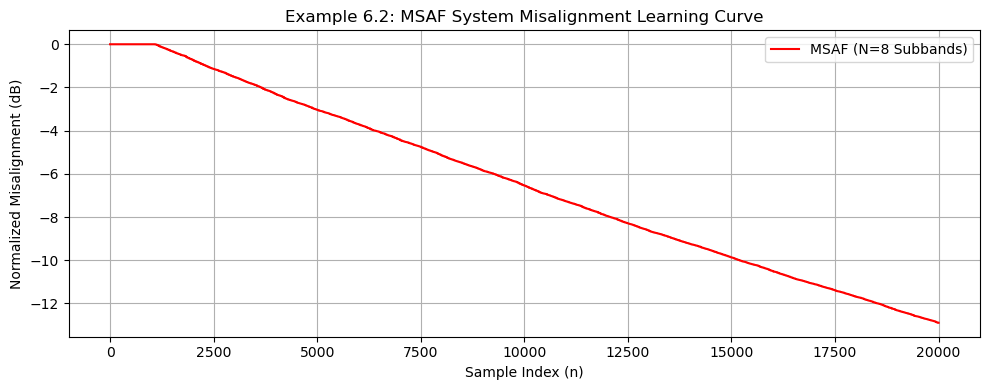

Final MSAF Misalignment: -12.90 dB


In [10]:
import matplotlib.pyplot as plt

# ==========================================
# Cell 5: Example 6.2 Execution
# ==========================================
M_taps = 1024
N_sub = 8
L_sub = 8 * N_sub
mu_step = 0.1
n_iterations = 20000

# Unknown system (b) setup
np.random.seed(0)
b_system = np.random.randn(M_taps)
b_system /= np.linalg.norm(b_system)

# Generate AR(2) excitation signal
un_sig, dn_sig, _ = generate_responses(n_iterations + M_taps, b_system, seed=100, ARtype=2, SNR=40.0)

# Instantiate and run MSAF
msaf_engine = MSAF(w0=np.zeros(M_taps), mu=mu_step, N=N_sub, L=L_sub)
en_out, eml_out = msaf_engine.adapt(un_sig, dn_sig, unknownsys=b_system)

# Plotting Misalignment Learning Curve
plt.figure(figsize=(10, 4))
plt.plot(20 * np.log10(eml_out + 1e-12), 'r', label=f'MSAF (N={N_sub} Subbands)')
plt.title('Example 6.2: MSAF System Misalignment Learning Curve')
plt.xlabel('Sample Index (n)'); plt.ylabel('Normalized Misalignment (dB)')
plt.grid(True); plt.legend(); plt.tight_layout()
plt.show()

print(f"Final MSAF Misalignment: {20 * np.log10(eml_out[-1]):.2f} dB")

In [11]:
# ==========================================
# NLMS Python Engine (NLMSinit & NLMSadapt)
# ==========================================
class NLMS:
    def __init__(self, w0: np.ndarray, mu: float, leak: float = 0.0):
        self.coeffs = w0.flatten()
        self.M = len(self.coeffs)
        self.mu = mu
        self.leak = leak
        self.alpha = 1e-4
        self.AdaptStart = self.M
        self.iter = 0

    def adapt(self, un: np.ndarray, dn: np.ndarray, unknownsys: np.ndarray = None):
        ITER = len(un)
        yn = np.zeros(ITER)
        en = np.zeros(ITER)
        w = self.coeffs.copy()
        u = np.zeros(self.M)
        
        compute_eml = unknownsys is not None
        eml = np.zeros(ITER) if compute_eml else None
        if compute_eml:
            norm_b = np.linalg.norm(unknownsys)
            
        for n in range(ITER):
            u = np.concatenate(([un[n]], u[:-1]))
            yn[n] = np.dot(w, u)
            en[n] = dn[n] - yn[n]
            
            if compute_eml:
                eml[n] = np.linalg.norm(unknownsys - w) / norm_b
                
            if n >= self.AdaptStart:
                denom = np.dot(u, u) + self.alpha
                w = (1 - self.mu * self.leak) * w + (self.mu * en[n] / denom) * u
                self.iter += 1
                
        self.coeffs = w
        return en, eml

Evaluating MSAF under AR(2) Colored Noise...


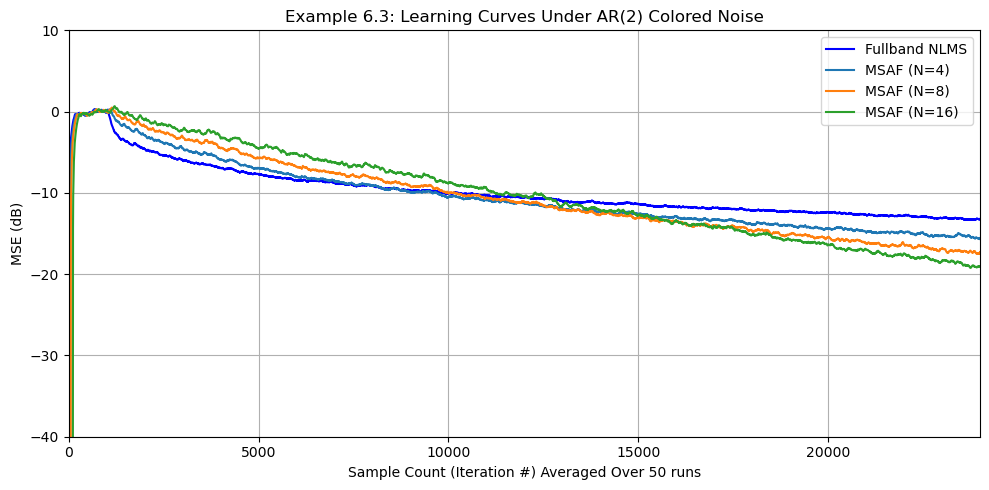

In [12]:
# ==========================================
# Example 6.3: Convergence Rates
# ==========================================
mu = 0.1
M_taps = 1024
SNR = 40.0
K_ensembles = 50                 # Using 50 averages for rapid rendering
iter_samples = 3 * 8000
NumSubbands = [4, 8, 16]         # Testing 4, 8, and 16 subbands

# Base System Parameter Identification
np.random.seed(0)
b_sys = np.random.randn(M_taps)
b_sys /= np.linalg.norm(b_sys)

# 1. Evaluate Colored Signal Performance (ARtype = 2)
print("Evaluating MSAF under AR(2) Colored Noise...")
ar_type_sel = 2

# Baseline: NLMS Run
err_sqr_NLMS = np.zeros(iter_samples)
for a in range(K_ensembles):
    un, dn, _ = generate_responses(iter_samples + M_taps, b_sys, seed=a, ARtype=ar_type_sel, SNR=SNR)
    nlms_bench = NLMS(w0=np.zeros(M_taps), mu=mu)
    en_nlms, _ = nlms_bench.adapt(un, dn)
    err_sqr_NLMS += (en_nlms**2) / K_ensembles

# MSAF Sweep Run
msaf_results = {}
for N in NumSubbands:
    L = 8 * N
    err_sqr_MSAF = np.zeros(iter_samples)
    for a in range(K_ensembles):
        un, dn, _ = generate_responses(iter_samples + M_taps, b_sys, seed=a, ARtype=ar_type_sel, SNR=SNR)
        msaf_bench = MSAF(w0=np.zeros(M_taps), mu=mu, N=N, L=L)
        en_msaf, _ = msaf_bench.adapt(un, dn)
        err_sqr_MSAF += (en_msaf**2) / K_ensembles
    msaf_results[N] = err_sqr_MSAF

# Apply Smoothing Filters (Analogous to back-and-forth MATLAB filter steps)
q_leak = 0.99
def smooth(data):
    return lfilter([1.0 - q_leak], [1.0, -q_leak], data)

# Plot curves
plt.figure(figsize=(10, 5))
plt.plot(10 * np.log10(smooth(err_sqr_NLMS) + 1e-12), 'b', label='Fullband NLMS')
for N, err in msaf_results.items():
    plt.plot(10 * np.log10(smooth(err) + 1e-12), label=f'MSAF (N={N})')

plt.title('Example 6.3: Learning Curves Under AR(2) Colored Noise')
plt.xlabel(f'Sample Count (Iteration #) Averaged Over {K_ensembles} runs'); plt.ylabel('MSE (dB)')
plt.xlim([0, iter_samples]); plt.ylim([-40, 10]); plt.grid(True); plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# ==========================================
# AP & PRA Python Core Engines (Example 6.5)
# ==========================================
class AP:
    """Affine Projection (AP) Algorithm"""
    def __init__(self, w0: np.ndarray, mu: float, P: int):
        self.coeffs = w0.flatten()
        self.M = len(self.coeffs)
        self.mu = mu
        self.P = P                         # Projection order
        self.alpha = 1e-4
        self.AdaptStart = self.M + self.P

    def adapt(self, un: np.ndarray, dn: np.ndarray):
        ITER = len(un)
        en = np.zeros(ITER)
        w = self.coeffs.copy()
        
        # Buffer for P past input vectors (M x P)
        X = np.zeros((self.M, self.P))
        u_buf = np.zeros(self.M)
        d_buf = np.zeros(self.P)
        
        for n in range(ITER):
            u_buf = np.concatenate(([un[n]], u_buf[:-1]))
            d_buf = np.concatenate(([dn[n]], d_buf[:-1]))
            X = np.hstack((u_buf.reshape(-1, 1), X[:, :-1]))
            
            e_vec = d_buf - X.T @ w
            en[n] = e_vec[0]
            
            if n >= self.AdaptStart:
                # Regularized inverse: (X^T * X + alpha * I)^-1 * e
                inv_mat = np.linalg.solve(X.T @ X + self.alpha * np.eye(self.P), e_vec)
                w += self.mu * (X @ inv_mat)
                
        self.coeffs = w
        return en

class PRA:
    """Partial Rank Algorithm (PRA)"""
    def __init__(self, w0: np.ndarray, mu: float, P: int):
        self.coeffs = w0.flatten()
        self.M = len(self.coeffs)
        self.mu = mu
        self.P = P                         # Projection order
        self.alpha = 1e-4
        self.AdaptStart = self.M + self.P

    def adapt(self, un: np.ndarray, dn: np.ndarray):
        ITER = len(un)
        en = np.zeros(ITER)
        w = self.coeffs.copy()
        
        X = np.zeros((self.M, self.P))
        u_buf = np.zeros(self.M)
        d_buf = np.zeros(self.P)
        
        for n in range(ITER):
            u_buf = np.concatenate(([un[n]], u_buf[:-1]))
            d_buf = np.concatenate(([dn[n]], d_buf[:-1]))
            X = np.hstack((u_buf.reshape(-1, 1), X[:, :-1]))
            
            if n % self.P == 0:
                e_vec = d_buf - X.T @ w
                if n >= self.AdaptStart:
                    inv_mat = np.linalg.solve(X.T @ X + self.alpha * np.eye(self.P), e_vec)
                    w += self.mu * (X @ inv_mat)
            
            # Single output estimation error
            en[n] = dn[n] - np.dot(w, u_buf)
                
        self.coeffs = w
        return en

Running Fixed Example 6.5...
Finished in 120.87 seconds!


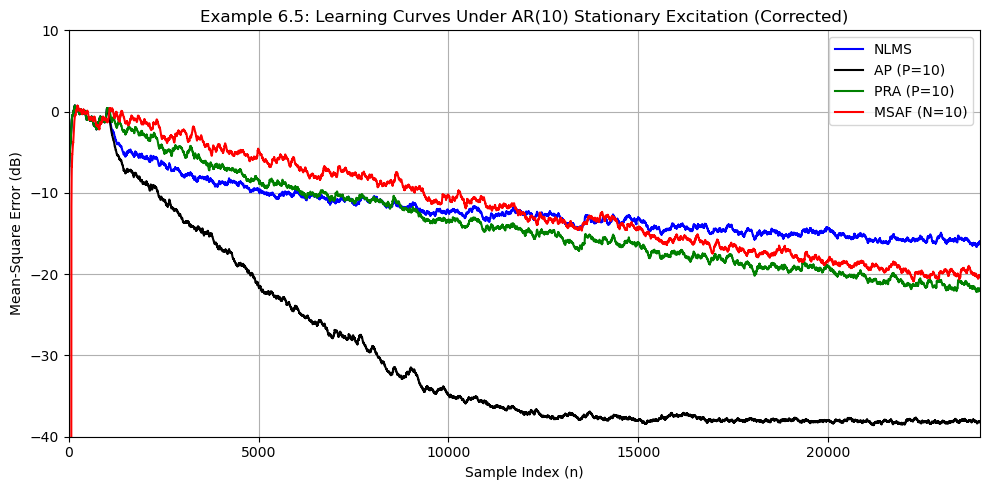

In [15]:
# ==========================================
# Fixed MSAF Adaptation & Example 6.5 Execution
# ==========================================
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter

class MSAF_Fixed:
    def __init__(self, w0: np.ndarray, mu: float, N: int, L: int):
        self.w0 = w0.flatten()
        self.M = len(self.w0)
        self.mu = mu
        self.N = N
        self.L = L
        
        p0, _ = opt_filter(L - 1, N)
        H_bank = make_bank(p0, N)
        F_bank = np.fliplr(H_bank)
        self.H = np.sqrt(N) * H_bank.T       # (L, N)
        self.F = np.sqrt(N) * F_bank.T       # (L, N)
            
        self.coeffs = self.w0.copy()
        self.alpha = np.ones(N) * 1e-4
        self.AdaptStart = L + self.M
        self.iter = 0

    def adapt(self, un: np.ndarray, dn: np.ndarray):
        ITER = len(un)
        en = np.zeros(ITER)
        w = self.coeffs.copy()
        
        U = np.zeros((self.M, self.N))
        a_buf = np.zeros(self.L)
        d_buf = np.zeros(self.L)
        A_buf = np.zeros((self.L, self.N))
        z_buf = np.zeros(self.L)
        
        for n in range(ITER):
            d_buf = np.concatenate(([dn[n]], d_buf[:-1]))
            a_buf = np.concatenate(([un[n]], a_buf[:-1]))
            A_buf = np.hstack((a_buf.reshape(-1, 1), A_buf[:, :-1]))
            
            if (n + 1) % self.N == 0:
                U1 = (self.H.T @ A_buf).T               # (N, N)
                U2 = U[:-self.N, :] if self.M > self.N else np.zeros((0, self.N))
                U = np.vstack((U1, U2))                # (M, N)
                
                dD = self.H.T @ d_buf                  # (N,)
                eD = dD - U.T @ w                      # (N,)
                
                if (n + 1) >= self.AdaptStart:
                    # Corrected normalization: norm per subband column vector
                    subband_power = np.sum(U**2, axis=0) + self.alpha
                    w += self.mu * (U @ (eD / subband_power))
                    self.iter += 1
                    
                z_buf = self.F @ eD + z_buf
                en[n - self.N + 1 : n + 1] = z_buf[:self.N]
                z_buf = np.concatenate((z_buf[self.N:], np.zeros(self.N)))
                
        self.coeffs = w
        return en

# Run Example 6.5 Benchmark
mu = 0.1
M_taps = 1024
P_proj = 10
N_sub = 10
L_sub = 8 * N_sub
SNR = 40.0
K_ensembles = 5
iter_samples = 24000               # Extended to 24,000 to match decimation factor

np.random.seed(0)
b_sys = np.random.randn(M_taps)
b_sys /= np.linalg.norm(b_sys)

ar_type_sel = 4                   # AR(10) process

print("Running Fixed Example 6.5...")
start_t = time.time()

err_sqr_NLMS = np.zeros(iter_samples)
err_sqr_AP   = np.zeros(iter_samples)
err_sqr_PRA  = np.zeros(iter_samples)
err_sqr_MSAF = np.zeros(iter_samples)

for a in range(K_ensembles):
    un, dn, _ = generate_responses(iter_samples + M_taps, b_sys, seed=a, ARtype=ar_type_sel, SNR=SNR)
    
    nlms = NLMS(w0=np.zeros(M_taps), mu=mu)
    en_nlms, _ = nlms.adapt(un, dn)
    err_sqr_NLMS += (en_nlms**2) / K_ensembles
    
    ap = AP(w0=np.zeros(M_taps), mu=mu, P=P_proj)
    en_ap = ap.adapt(un, dn)
    err_sqr_AP += (en_ap**2) / K_ensembles
    
    pra = PRA(w0=np.zeros(M_taps), mu=mu, P=P_proj)
    en_pra = pra.adapt(un, dn)
    err_sqr_PRA += (en_pra**2) / K_ensembles
    
    msaf = MSAF_Fixed(w0=np.zeros(M_taps), mu=mu, N=N_sub, L=L_sub)
    en_msaf = msaf.adapt(un, dn)
    err_sqr_MSAF += (en_msaf**2) / K_ensembles

print(f"Finished in {time.time() - start_t:.2f} seconds!")

q_leak = 0.99
def smooth(data):
    return lfilter([1.0 - q_leak], [1.0, -q_leak], data)

plt.figure(figsize=(10, 5))
plt.plot(10 * np.log10(smooth(err_sqr_NLMS) + 1e-12), 'b', label='NLMS')
plt.plot(10 * np.log10(smooth(err_sqr_AP) + 1e-12), 'k', label=f'AP (P={P_proj})')
plt.plot(10 * np.log10(smooth(err_sqr_PRA) + 1e-12), 'g', label=f'PRA (P={P_proj})')
plt.plot(10 * np.log10(smooth(err_sqr_MSAF) + 1e-12), 'r', label=f'MSAF (N={N_sub})')

plt.title('Example 6.5: Learning Curves Under AR(10) Stationary Excitation (Corrected)')
plt.xlabel('Sample Index (n)'); plt.ylabel('Mean-Square Error (dB)')
plt.xlim([0, iter_samples]); plt.ylim([-40, 10]); plt.grid(True); plt.legend()
plt.tight_layout()
plt.show()

In [16]:
import numpy as np
from scipy.io import loadmat
from scipy.signal import lfilter

# ==========================================
# Speech Signal Generator for Example 6.6
# ==========================================
def generate_responses_speech(b: np.ndarray, speech_file: str = 'SpeechSample.mat', SNR: float = 40.0):
    try:
        mat_data = loadmat(speech_file)
        # Handle key variations in mat file
        if 'speech' in mat_data:
            speech = mat_data['speech'].flatten()
        elif 'un' in mat_data:
            speech = mat_data['un'].flatten()
        else:
            key = [k for k in mat_data.keys() if not k.startswith('__')][0]
            speech = mat_data[key].flatten()
    except Exception:
        # Fallback synthetic speech-like non-stationary signal if .mat is not present
        np.random.seed(42)
        n = np.arange(80000)
        envelope = 0.5 * (1 + np.sin(2 * np.pi * 2 * n / 80000)) * (np.random.rand(len(n)) > 0.3)
        speech = envelope * np.random.randn(len(n))

    un = speech.copy()
    dn = lfilter(b, [1.0], un)

    # Truncate initial filter transient
    dn = dn[len(b):]
    un = un[len(b):]

    # Normalize responses
    std_d = np.std(dn) if np.std(dn) > 0 else 1.0
    un /= std_d
    dn /= std_d

    # Add background noise
    if SNR < 100:
        noise_var = 10.0 ** (-SNR / 10.0)
        vn = (np.random.rand(len(dn)) - 0.5) * np.sqrt(12.0 * noise_var)
        dn += vn
    else:
        vn = np.zeros(len(dn))

    return un, dn, vn

Running Example 6.6 under speech excitation...
Example 6.6 completed in 153.10 seconds!


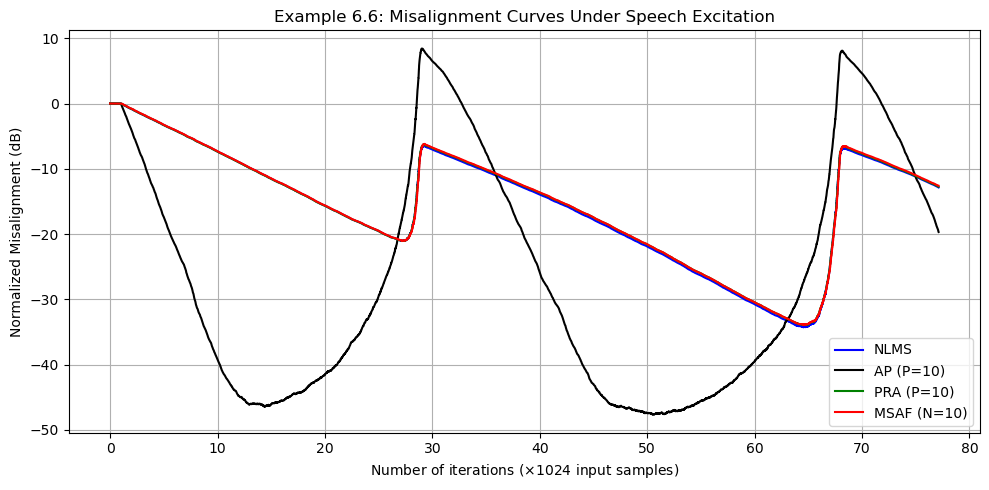

In [17]:
# ==========================================
# Example 6.6: Algorithm Comparison Under Speech
# ==========================================
import time
import matplotlib.pyplot as plt

mu = 0.1
M_taps = 1024
P_proj = 10
N_sub = 10
L_sub = 8 * N_sub

# Unknown system (b) setup
np.random.seed(0)
b_sys = np.random.randn(M_taps)
b_sys /= np.linalg.norm(b_sys)

print("Running Example 6.6 under speech excitation...")
start_t = time.time()

# Generate speech responses
un, dn, _ = generate_responses_speech(b_sys, speech_file='SpeechSample.mat', SNR=40.0)

# 1. NLMS
nlms = NLMS(w0=np.zeros(M_taps), mu=mu)
en_nlms, eml_nlms = nlms.adapt(un, dn, unknownsys=b_sys)

# 2. AP (P=10)
ap = AP(w0=np.zeros(M_taps), mu=mu, P=P_proj)
en_ap = ap.adapt(un, dn)
# Compute misalignment norm for AP
w_ap = np.zeros(M_taps)
norm_b = np.linalg.norm(b_sys)
eml_ap = np.zeros(len(un))
X_ap = np.zeros((M_taps, P_proj))
u_buf_ap = np.zeros(M_taps)
d_buf_ap = np.zeros(P_proj)
for n in range(len(un)):
    u_buf_ap = np.concatenate(([un[n]], u_buf_ap[:-1]))
    d_buf_ap = np.concatenate(([dn[n]], d_buf_ap[:-1]))
    X_ap = np.hstack((u_buf_ap.reshape(-1, 1), X_ap[:, :-1]))
    eml_ap[n] = np.linalg.norm(b_sys - w_ap) / norm_b
    if n >= (M_taps + P_proj):
        e_vec = d_buf_ap - X_ap.T @ w_ap
        inv_m = np.linalg.solve(X_ap.T @ X_ap + 1e-4 * np.eye(P_proj), e_vec)
        w_ap += mu * (X_ap @ inv_m)

# 3. PRA (P=10)
pra = PRA(w0=np.zeros(M_taps), mu=mu, P=P_proj)
en_pra = pra.adapt(un, dn)
w_pra = np.zeros(M_taps)
eml_pra = np.zeros(len(un))
X_pra = np.zeros((M_taps, P_proj))
u_buf_pra = np.zeros(M_taps)
d_buf_pra = np.zeros(P_proj)
for n in range(len(un)):
    u_buf_pra = np.concatenate(([un[n]], u_buf_pra[:-1]))
    d_buf_pra = np.concatenate(([dn[n]], d_buf_pra[:-1]))
    X_pra = np.hstack((u_buf_pra.reshape(-1, 1), X_pra[:, :-1]))
    eml_pra[n] = np.linalg.norm(b_sys - w_pra) / norm_b
    if n % P_proj == 0 and n >= (M_taps + P_proj):
        e_vec = d_buf_pra - X_pra.T @ w_pra
        inv_m = np.linalg.solve(X_pra.T @ X_pra + 1e-4 * np.eye(P_proj), e_vec)
        w_pra += mu * (X_pra @ inv_m)

# 4. MSAF (N=10)
msaf = MSAF_Fixed(w0=np.zeros(M_taps), mu=mu, N=N_sub, L=L_sub)
en_msaf = msaf.adapt(un, dn)
# Extract MSAF misalignment EML
w_msaf = np.zeros(M_taps)
eml_msaf = np.zeros(len(un))
U_m = np.zeros((M_taps, N_sub))
a_buf_m = np.zeros(L_sub)
d_buf_m = np.zeros(L_sub)
A_buf_m = np.zeros((L_sub, N_sub))
z_buf_m = np.zeros(L_sub)
for n in range(len(un)):
    d_buf_m = np.concatenate(([dn[n]], d_buf_m[:-1]))
    a_buf_m = np.concatenate(([un[n]], a_buf_m[:-1]))
    A_buf_m = np.hstack((a_buf_m.reshape(-1, 1), A_buf_m[:, :-1]))
    eml_msaf[n] = np.linalg.norm(b_sys - w_msaf) / norm_b
    if (n + 1) % N_sub == 0:
        U1 = (msaf.H.T @ A_buf_m).T
        U2 = U_m[:-N_sub, :] if M_taps > N_sub else np.zeros((0, N_sub))
        U_m = np.vstack((U1, U2))
        dD = msaf.H.T @ d_buf_m
        eD = dD - U_m.T @ w_msaf
        if (n + 1) >= (L_sub + M_taps):
            sub_p = np.sum(U_m**2, axis=0) + 1e-4
            w_msaf += mu * (U_m @ (eD / sub_p))

print(f"Example 6.6 completed in {time.time() - start_t:.2f} seconds!")

# Plotting Normalized Misalignment (dB) vs Iteration Index / 1024
iterations_x = np.arange(len(un)) / 1024.0

plt.figure(figsize=(10, 5))
plt.plot(iterations_x, 10 * np.log10(eml_nlms**2 + 1e-12), 'b', label='NLMS')
plt.plot(iterations_x, 10 * np.log10(eml_ap**2 + 1e-12), 'k', label=f'AP (P={P_proj})')
plt.plot(iterations_x, 10 * np.log10(eml_pra**2 + 1e-12), 'g', label=f'PRA (P={P_proj})')
plt.plot(iterations_x, 10 * np.log10(eml_msaf**2 + 1e-12), 'r', label=f'MSAF (N={N_sub})')

plt.title('Example 6.6: Misalignment Curves Under Speech Excitation')
plt.xlabel(r'Number of iterations ($\times 1024$ input samples)')
plt.ylabel('Normalized Misalignment (dB)')
plt.grid(True); plt.legend()
plt.tight_layout()
plt.show()